# Section Condition × Rerank Alpha Sweep Analysis

Evaluates how the **set of indexed sections** and the **reranking alpha parameter** jointly affect answer quality.
Runs the T21 RAG pipeline in a 2D sweep: 3 section conditions × 6 alpha values, with LLM-as-judge disabled for speed.

**Rerank alpha (α):** blends vector similarity and cross-encoder reranking score:
`combined = α × vector_score_norm + (1 − α) × cross_encoder_score_scaled`
(0.0 = pure cross-encoder; 1.0 = pure vector similarity)

| Condition | Sections | Rationale |
|-----------|----------|-----------|
| **C1** | Abstract, Introduction | Background / context only |
| **C2** | Abstract, Introduction, Results, Discussion, Methods, Conclusion | Full corpus (all 6 sections) |
| **C3** | Results, Discussion, Methods, Conclusion | Evidence-only (current production default) |

**Alpha values swept:** `[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]`  
**LLM-as-judge:** disabled (`enable_judge=False`) for all sweep calls (speed).

**Metrics:** BERTScore Precision / Recall / F (sentence-level cosine via `nvidia/llama-nemotron-embed-vl-1b-v2`, 2048-dim) + semantic similarity (document-level cosine). Embeddings computed via the production `/embed_batch` API endpoint — the same DeepInfra model used to index the corpus.

**Output:** `analysis/output/section_condition/`

| File | Description |
|------|-------------|
| `responses_section_alpha_sweep.csv` | Raw summaries — one row per (condition, alpha, question) |
| `bertscores_section_alpha_sweep.csv` | BERTScore P/R/F + SemanticSim per row |
| `section_alpha_heatmap.pdf/.jpg` | Heatmap: condition × alpha, BERTScore F & SemanticSim |
| `section_alpha_barchart.pdf/.jpg` | Grouped bar chart: BERTScore F & SemanticSim vs alpha, one bar group per condition |

## Cell 1 — Configuration

Sets all runtime parameters for the 2D sweep.

| Parameter | Value | Description |
|-----------|-------|-------------|
| `BACKEND_URL` | `http://127.0.0.1:8698` | T21 RAG FastAPI endpoint |
| `TOP_K` | `20` | Retrieval candidates per query |
| `ALPHA_VALUES` | `[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]` | Rerank blend values to sweep |
| `ENABLE_JUDGE` | `False` | LLM-as-judge disabled for all sweep calls |
| `SAVE_DPI` | `300` | Output figure resolution |

**Section conditions:**

| Label | Sections retrieved | Notes |
|-------|--------------------|-------|
| `C1` | Abstract, Introduction | Background / context only — no primary evidence |
| `C2` | Abstract, Introduction, Results, Discussion, Methods, Conclusion | Full 6-section corpus |
| `C3` | Results, Discussion, Methods, Conclusion | Evidence-only — current production default |

**Embedding model (BERTScore):** `nvidia/llama-nemotron-embed-vl-1b-v2` (2048-dim) via the production `/embed_batch` API endpoint — the same model used to index the corpus, ensuring retrieval and evaluation are in the same embedding space.

In [ ]:
import os
from pathlib import Path
from dotenv import load_dotenv

_NB_DIR  = Path('..').resolve()          # analysis/
_SRV_DIR = _NB_DIR.parent / 'srv'
load_dotenv(_NB_DIR / '.env')

OUTPUT_DIR = _NB_DIR / 'output' / 'section_condition'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BACKEND_URL = os.getenv('BACKEND_URL', 'http://127.0.0.1:8698')
# Embeddings for BERTScore use the production /embed_batch endpoint
# → DeepInfra nvidia/llama-nemotron-embed-vl-1b-v2 (2048-dim), same model as the RAG pipeline

QUESTIONS_XLSX = (
    _NB_DIR / 'input'
    / 'AI_research_assistant_Sample_questions_revised_JIM_Negative_Ctrl_dt_03_12_2026.xlsx'
)

TOP_K    = 20
SAVE_DPI = 300

# ── Section conditions ────────────────────────────────────────────────────────
CONDITIONS = {
    'C1: Abstract + Introduction': [
        'Abstract', 'Introduction',
    ],
    'C2: Full Corpus (all 6 sections)': [
        'Abstract', 'Introduction', 'Results', 'Discussion', 'Methods', 'Conclusion',
    ],
    'C3: Evidence-only (Results + Discussion + Methods + Conclusion)': [
        'Results', 'Discussion', 'Methods', 'Conclusion',
    ],
}

# ── Rerank alpha sweep ────────────────────────────────────────────────────────
# combined = alpha * vector_score_norm + (1 - alpha) * cross_encoder_score_scaled
# 0.0 = pure cross-encoder reranking; 1.0 = pure vector similarity
ALPHA_VALUES = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

# Disable LLM-as-judge for all sweep calls (speed; per-request override in main.py)
ENABLE_JUDGE = False

print(f'API URL      : {BACKEND_URL}')
print(f'Questions    : {QUESTIONS_XLSX.name}  (exists={QUESTIONS_XLSX.exists()})')
print(f'Output       : {OUTPUT_DIR}')
print(f'Alpha values : {ALPHA_VALUES}')
print(f'Enable Judge : {ENABLE_JUDGE}')
print()
for cname, secs in CONDITIONS.items():
    print(f'  {cname}')
    print(f'    → {secs}')

## Cell 2 — Imports

Loads all required libraries and configures global Matplotlib style settings.

| Library | Purpose |
|---------|---------|
| `requests` | HTTP calls to the T21 RAG API (`/answer`, `/embed_batch`) |
| `numpy` | Cosine similarity matrix computation for BERTScore |
| `pandas` | DataFrames for responses, scores, and pivot tables |
| `matplotlib` / `seaborn` | Heatmaps and line charts |
| `tqdm` | Progress bars for the sweep loop |

No OpenAI client is imported — all embeddings go through the production `/embed_batch` endpoint.

In [ ]:
import re
import time
from typing import List

import numpy as np
import pandas as pd
import requests
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

mpl.rcParams.update({
    'font.family'       : 'sans-serif',
    'font.size'         : 13,
    'axes.titlesize'    : 15,
    'axes.titleweight'  : 'bold',
    'axes.labelsize'    : 13,
    'xtick.labelsize'   : 11,
    'ytick.labelsize'   : 11,
    'legend.fontsize'   : 10,
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'figure.facecolor'  : 'white',
    'axes.facecolor'    : 'white',
    'pdf.fonttype'      : 42,
    'ps.fonttype'       : 42,
})
print('Imports OK')

## Cell 3 — Load Questions & Ground Truth

Reads the benchmark question set from the evaluation Excel file and filters to **positive-control questions** that have a ground-truth answer.

**Source file:** `AI_research_assistant_Sample_questions_revised_JIM_Negative_Ctrl_dt_03_12_2026.xlsx`  
**Sheet:** `Questions_for_testing`

**Columns used:**

| Column | Description |
|--------|-------------|
| `Original question` | The research question sent to the RAG pipeline |
| `Answer` | Expert ground-truth answer used as BERTScore reference |
| `CTRL_Type` | `positive` (answerable) or `negative` (unanswerable) |

Only rows with `CTRL_Type == 'positive'` and a non-empty `Answer` are included. Negative controls (intentionally unanswerable questions) are excluded because they have no valid ground-truth reference for scoring.

In [ ]:
df_q = pd.read_excel(QUESTIONS_XLSX, sheet_name='Questions_for_testing')
df_q.columns = df_q.columns.str.strip()

# Keep positive controls with a ground-truth answer
df_pos = df_q[
    (df_q['CTRL_Type'].str.lower() == 'positive') &
    df_q['Answer'].notna() &
    (df_q['Answer'].str.strip() != '')
].reset_index(drop=True)

questions  = df_pos['Original question'].tolist()
gt_answers = df_pos['Answer'].tolist()

print(f'Positive-control questions with GT: {len(questions)}')
for i, q in enumerate(questions):
    print(f'  Q{i+1:02d}: {q[:90]}')

## Cell 4 — Generate Responses: 2D Sweep (Conditions × Alpha)

Calls `POST /answer` for every combination of section condition and rerank alpha value.

**Per-request parameters:**

| Parameter | Value | Notes |
|-----------|-------|-------|
| `sections` | condition-specific list | Restricts Milvus retrieval to these sections only |
| `rerank_alpha` | swept 0.0 → 1.0 | Overrides `RERANK_ALPHA` from `.env` for this request |
| `enable_judge` | `False` | Skips the `judge_improve` LangGraph node (saves ~15–30 s per call) |
| `top_k` | `20` | Retrieval candidates before reranking |
| `timeout` | 180 s | Per-request HTTP timeout |

**Total API calls:** 3 conditions × 6 alpha values × N questions  
(e.g. 3 × 6 × 20 = **360 calls** for 20 questions)

**`_extract_summary`:** strips `[PMCxxxxxxx:Section](url)` citation links from the returned markdown before scoring, so BERTScore operates on clean prose text.

**`_call_api`:** returns an empty string on any HTTP or timeout error; the scoring step handles empty strings gracefully (returns 0.0).

In [ ]:
def _extract_summary(markdown: str) -> str:
    """Extract the # Summary body; strip inline PMC citation tags."""
    m = re.search(r'(?im)^#\s+Summary\s*\n(.*?)(?=^#\s+|\Z)', markdown, re.S)
    body = m.group(1).strip() if m else markdown.strip()
    body = re.sub(r'\[PMC[^\]]+\](?:\([^)]*\))?', '', body)
    return body.strip()


def _call_api(question: str, sections: List[str], alpha: float,
              top_k: int = TOP_K, enable_judge: bool = False) -> str:
    """POST /answer with explicit section list, rerank_alpha, and enable_judge flag."""
    try:
        r = requests.post(
            f'{BACKEND_URL}/answer',
            json={
                'question'    : question,
                'top_k'       : top_k,
                'sections'    : sections,
                'rerank_alpha': alpha,
                'enable_judge': enable_judge,
            },
            timeout=180,
        )
        r.raise_for_status()
        md = r.json().get('markdown', '')
        return _extract_summary(md)
    except Exception as e:
        print(f'    [ERROR] {e}')
        return ''


# ── 2D sweep: conditions × alpha ─────────────────────────────────────────────
# results[cname][alpha] = list of summaries (one per question)
results = {cname: {a: [] for a in ALPHA_VALUES} for cname in CONDITIONS}

total_calls = len(CONDITIONS) * len(ALPHA_VALUES) * len(questions)
done = 0

for cname, sections in CONDITIONS.items():
    for alpha in ALPHA_VALUES:
        tag = f'{cname.split(":")[0]}  α={alpha}'
        print(f'\n── {tag} ──')
        for q in tqdm(questions, desc=f'{tag[:40]}'):
            summary = _call_api(q, sections, alpha, enable_judge=ENABLE_JUDGE)
            results[cname][alpha].append(summary)
            done += 1
            time.sleep(0.3)

print(f'\nDone. {done}/{total_calls} responses collected.')

## Cell 4b — Checkpoint: Save Raw Responses

Flattens the 3D result structure `results[condition][alpha][question_idx]` into a tidy DataFrame and saves to CSV immediately after generation — before any scoring step — so results are preserved even if scoring is interrupted.

**Output file:** `responses_section_alpha_sweep.csv`

**Schema:**

| Column | Description |
|--------|-------------|
| `q_idx` | 1-based question index |
| `question` | Full question text |
| `ground_truth` | Expert reference answer |
| `condition` | Section condition label (e.g. `C3: Evidence-only...`) |
| `alpha` | Rerank alpha value (0.0 – 1.0) |
| `summary` | Cleaned summary text returned by the RAG pipeline |

Also prints mean word counts per (condition, alpha) cell as a sanity check — unexpectedly short word counts indicate failed or evidence-gap responses.

In [ ]:
rows = []
for cname in CONDITIONS:
    for alpha in ALPHA_VALUES:
        for i, (q, gt) in enumerate(zip(questions, gt_answers)):
            rows.append({
                'q_idx'       : i + 1,
                'question'    : q,
                'ground_truth': gt,
                'condition'   : cname,
                'alpha'       : alpha,
                'summary'     : results[cname][alpha][i],
            })

df_resp = pd.DataFrame(rows)
csv_path = OUTPUT_DIR / 'responses_section_alpha_sweep.csv'
df_resp.to_csv(csv_path, index=False)
print(f'Saved → {csv_path}  ({len(df_resp)} rows)')

# Word-count sanity check
print('\nMean summary word counts (condition × alpha):')
for cname in CONDITIONS:
    c_short = cname.split(':')[0].strip()
    for alpha in ALPHA_VALUES:
        sub  = df_resp[(df_resp['condition'] == cname) & (df_resp['alpha'] == alpha)]
        wcs  = [len(t.split()) for t in sub['summary'] if t.strip()]
        mean = np.mean(wcs) if wcs else 0
        print(f'  {c_short}  α={alpha:.1f}  → {mean:.0f} words  (n={len(wcs)})')

## Cell 5 — BERTScore & Semantic Similarity

Scores every (condition, alpha, question) row against its ground-truth answer using two complementary metrics.

**Embedding model:** `nvidia/llama-nemotron-embed-vl-1b-v2` (2048-dim) via `POST /embed_batch` on the production API — the same DeepInfra model used to embed the corpus. Using the same model for scoring as for retrieval ensures the similarity space is consistent.

---

### BERTScore (sentence-level)

Measures semantic overlap at the sentence level using cosine similarity between embedded sentences.

| Metric | Definition |
|--------|-----------|
| **Precision (P)** | For each candidate sentence, find the most similar reference sentence. Mean of these max-cosine values. High P = candidate doesn't hallucinate content absent from the reference. |
| **Recall (R)** | For each reference sentence, find the most similar candidate sentence. Mean of these max-cosine values. High R = candidate covers the key points in the reference. |
| **F-score (F)** | Harmonic mean of P and R. Primary ranking metric for this analysis. |

---

### Semantic Similarity (document-level)

Embeds the full candidate and reference as single vectors; returns their cosine similarity. Captures overall topical alignment rather than fine-grained sentence coverage.

---

**Output file:** `bertscores_section_alpha_sweep.csv` — one row per (condition, alpha, question) with columns `P`, `R`, `F`, `SS`.

In [ ]:
def _split_sentences(text: str) -> List[str]:
    parts = re.split(r'(?<=[.!?])\s+', text.strip())
    return [s.strip() for s in parts if len(s.strip()) > 10]


def _embed_batch(texts: List[str], _dim: list = [0]) -> np.ndarray:
    """Embed texts via the production /embed_batch endpoint.
    Uses the active embedder (DeepInfra nvidia/llama-nemotron-embed-vl-1b-v2, 2048-dim).
    Returns zero vectors on failure so scoring degrades gracefully.
    """
    try:
        r = requests.post(
            f'{BACKEND_URL}/embed_batch',
            json={'texts': texts},
            timeout=120,
        )
        r.raise_for_status()
        raw = r.text.strip()
        if not raw:
            print(f'    [EMBED_WARN] empty response body for {len(texts)} texts')
            fallback_dim = _dim[0] if _dim[0] else 2048
            return np.zeros((len(texts), fallback_dim), dtype=np.float32)
        data = r.json()
        arr = np.array(data['embeddings'], dtype=np.float32)
        _dim[0] = arr.shape[1]   # cache actual dim for fallback
        return arr
    except Exception as e:
        print(f'    [EMBED_ERROR] {e}')
        fallback_dim = _dim[0] if _dim[0] else 2048
        return np.zeros((len(texts), fallback_dim), dtype=np.float32)


def _cosine_matrix(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    a = a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-9)
    b = b / (np.linalg.norm(b, axis=1, keepdims=True) + 1e-9)
    return a @ b.T


def bert_score(candidate: str, reference: str) -> dict:
    """Sentence-level BERTScore P/R/F using DeepInfra embeddings."""
    cands = _split_sentences(candidate)
    refs  = _split_sentences(reference)
    if not cands or not refs:
        return {'P': 0.0, 'R': 0.0, 'F': 0.0}
    embs   = _embed_batch(cands + refs)
    c_embs = embs[:len(cands)]
    r_embs = embs[len(cands):]
    sim    = _cosine_matrix(c_embs, r_embs)
    P = float(sim.max(axis=1).mean())
    R = float(sim.max(axis=0).mean())
    F = 2 * P * R / (P + R + 1e-9)
    return {'P': P, 'R': R, 'F': F}


def semantic_sim(candidate: str, reference: str) -> float:
    """Document-level cosine similarity via DeepInfra embeddings."""
    if not candidate.strip() or not reference.strip():
        return 0.0
    embs = _embed_batch([candidate, reference])
    a    = embs[0] / (np.linalg.norm(embs[0]) + 1e-9)
    b    = embs[1] / (np.linalg.norm(embs[1]) + 1e-9)
    return float(a @ b)


# ── Smoke-test the embed endpoint before scoring ──────────────────────────────
_test = _embed_batch(['Down syndrome trisomy 21'])
print(f'Embed endpoint — shape: {_test.shape}  non-zero: {_test.any()}')
assert _test.ndim == 2 and _test.shape[0] == 1 and _test.any(), \
    f'Embed endpoint not working (shape={_test.shape}, all-zeros={not _test.any()}) — check API health'
print('Smoke test passed. Starting scoring...')

# ── Score every row ───────────────────────────────────────────────────────────
score_rows = []
for _, row in tqdm(df_resp.iterrows(), total=len(df_resp), desc='Scoring'):
    bs = bert_score(row['summary'], row['ground_truth'])
    ss = semantic_sim(row['summary'], row['ground_truth'])
    score_rows.append({
        'q_idx'    : row['q_idx'],
        'question' : row['question'][:70],
        'condition': row['condition'],
        'alpha'    : row['alpha'],
        'P'        : bs['P'],
        'R'        : bs['R'],
        'F'        : bs['F'],
        'SS'       : ss,
    })
    time.sleep(0.05)

df_scores = pd.DataFrame(score_rows)
df_scores.to_csv(OUTPUT_DIR / 'bertscores_section_alpha_sweep.csv', index=False)
print(f'Scored {len(df_scores)} rows → saved to bertscores_section_alpha_sweep.csv')

## Cell 6 — Mean Scores Pivot Table (Condition × Alpha)

Aggregates scores into two pivot tables — one for BERTScore F and one for Semantic Similarity — with **section condition as rows** and **rerank alpha as columns**.

Each cell shows the mean score across all positive-control questions for that (condition, alpha) combination.

**How to read the tables:**
- Moving **across a row** (left → right) shows the effect of increasing alpha (more vector weight, less cross-encoder) for a fixed section set.
- Moving **down a column** compares section conditions at a fixed alpha — reveals whether adding Abstract/Introduction sections helps or hurts.
- The **highest-scoring cell** per table identifies the optimal (condition, alpha) operating point.

These tables are the numerical basis for the heatmaps in Cell 7.

In [ ]:
# Pivot: mean BERTScore F per (condition × alpha)
df_pivot_F = df_scores.groupby(['condition', 'alpha'])['F'].mean().unstack('alpha')
df_pivot_F.index = [c.split(':')[0].strip() for c in df_pivot_F.index]
df_pivot_F.columns.name = 'alpha'

# Pivot: mean Semantic Similarity
df_pivot_SS = df_scores.groupby(['condition', 'alpha'])['SS'].mean().unstack('alpha')
df_pivot_SS.index = [c.split(':')[0].strip() for c in df_pivot_SS.index]
df_pivot_SS.columns.name = 'alpha'

pd.set_option('display.float_format', '{:.4f}'.format)
print('Mean BERTScore F  (condition × alpha):\n')
display(df_pivot_F)
print('\nMean Semantic Similarity  (condition × alpha):\n')
display(df_pivot_SS)

## Cell 7 — Heatmap: Section Condition × Rerank Alpha

Visualises the pivot tables from Cell 6 as annotated heatmaps.

**Layout:** two side-by-side panels — BERTScore F (left) and Semantic Similarity (right).  
**Color scale:** Blues, 0.0 – 1.0.  
**Annotation:** mean score printed in each cell (3 decimal places); darker = higher score.

**What to look for:**
- A **column of dark cells** at a particular alpha suggests that alpha value is broadly optimal regardless of section condition.
- A **row of dark cells** for a particular condition suggests that condition retrieves consistently higher-quality evidence.
- **Diagonal patterns** indicate an interaction: one condition may benefit from more vector weight while another benefits from more reranking.

**Output files:** `section_alpha_heatmap.pdf` and `section_alpha_heatmap.jpg` in `analysis/output/section_condition/`.

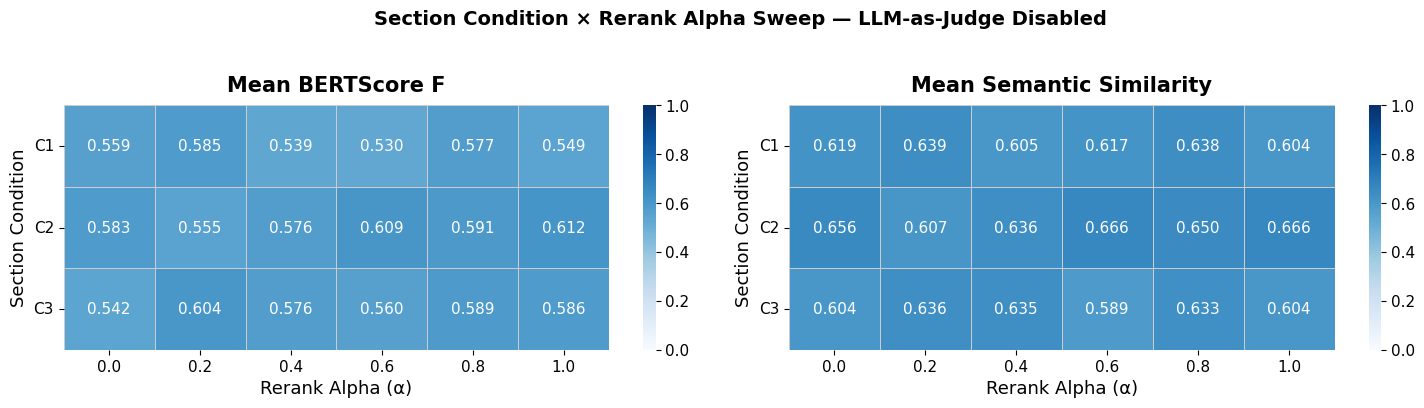

Saved → /path/to/project/T21_research_assistant_v6/analysis/output/section_condition/section_alpha_heatmap.{pdf,jpg}


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

for ax, pivot, title in zip(
    axes,
    [df_pivot_F,  df_pivot_SS],
    ['Mean BERTScore F', 'Mean Semantic Similarity'],
):
    sns.heatmap(
        pivot.astype(float), annot=True, fmt='.3f',
        cmap='Blues', vmin=0.0, vmax=1.0,
        linewidths=0.5, linecolor='#CCCCCC',
        annot_kws={'size': 11}, ax=ax,
    )
    ax.set_title(title, pad=10)
    ax.set_xlabel('Rerank Alpha (α)')
    ax.set_ylabel('Section Condition')
    ax.tick_params(axis='y', rotation=0)

fig.suptitle(
    'Section Condition × Rerank Alpha Sweep — LLM-as-Judge Disabled',
    fontsize=14, fontweight='bold', y=1.02,
)
plt.tight_layout()

for fmt, ext in [('pdf', 'pdf'), ('jpeg', 'jpg')]:
    fig.savefig(OUTPUT_DIR / f'section_alpha_heatmap.{ext}',
                dpi=SAVE_DPI, bbox_inches='tight', format=fmt)
plt.show()
print(f'Saved → {OUTPUT_DIR}/section_alpha_heatmap.{{pdf,jpg}}')

## Cell 8 — Bar Chart: BERTScore F & Semantic Similarity vs Rerank Alpha

Grouped bar chart with alpha on the x-axis, one bar group per alpha value, and three bars per group (one per section condition).

**Enhancements over a plain bar chart:**

| Feature | Description |
|---------|-------------|
| **Error bars** | ±1 SD across the 12 questions for each (condition, alpha) cell |
| **Grand mean line** | Dashed black line — mean of the three condition means at each alpha |
| **Grand mean band** | Shaded ±1 SD region around the grand mean, showing spread across conditions |
| **Significance brackets** | Paired Wilcoxon signed-rank test (same 12 questions per pair): C1 vs C3 and C2 vs C3 at each alpha; only significant comparisons are annotated (`*p<0.05`, `**p<0.01`, `***p<0.001`); `ns` brackets omitted for clarity |

**Pairs tested:** C1 (Abstract + Introduction) vs C3 (Evidence-only) and C2 (Full Corpus) vs C3 — comparing each non-default condition against the current production default.

**Output files:** `section_alpha_barchart.pdf` and `section_alpha_barchart.jpg` in `analysis/output/section_condition/`.

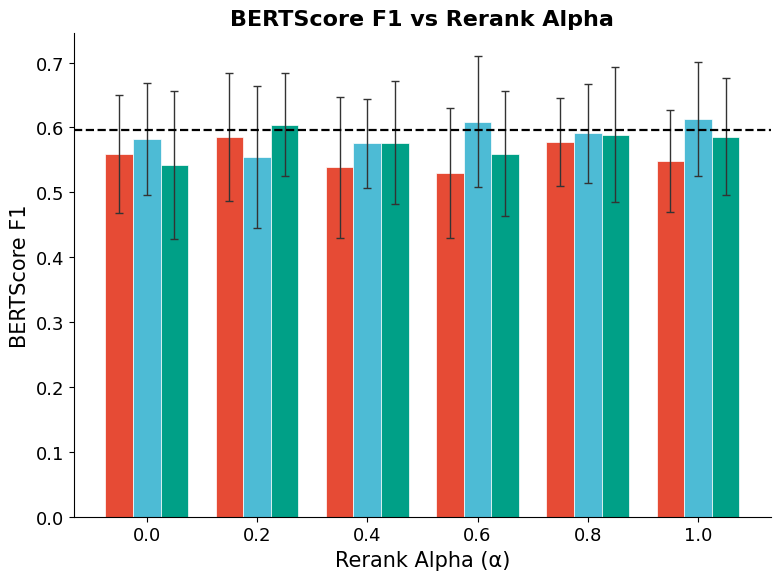

Saved → /path/to/project/T21_research_assistant_v6/analysis/output/section_condition/section_alpha_barchart_bertscore_f1.{pdf,jpg}
Saved → /path/to/project/T21_research_assistant_v6/analysis/output/section_condition/section_alpha_barchart_bertscore_f1_legend.{pdf,jpg}


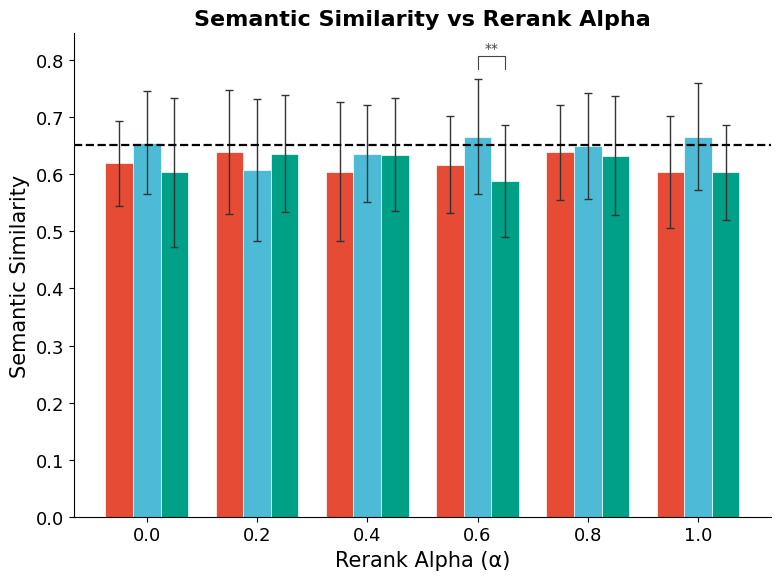

Saved → /path/to/project/T21_research_assistant_v6/analysis/output/section_condition/section_alpha_barchart_ss.{pdf,jpg}
Saved → /path/to/project/T21_research_assistant_v6/analysis/output/section_condition/section_alpha_barchart_ss_legend.{pdf,jpg}


In [21]:
from scipy import stats as sp_stats

_colors   = ['#E64B35', '#4DBBD5', '#00A087']   # NPG: red, cyan, teal
cond_list = list(CONDITIONS.keys())

n_alpha   = len(ALPHA_VALUES)
n_cond    = len(cond_list)
bar_width = 0.25
x         = np.arange(n_alpha)
offsets   = [(i - n_cond / 2 + 0.5) * bar_width for i in range(n_cond)]


def _sig_label(p):
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return None


def _bracket(ax, x1, x2, y, h, label, lw=0.8, fs=10):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=lw, c='#444')
    ax.text((x1 + x2) / 2, y + h + 0.003, label,
            ha='center', va='bottom', fontsize=fs, color='#444')


for metric, ylabel, fname_stem in [
    ('F',  'BERTScore F1',         'section_alpha_barchart_bertscore_f1'),
    ('SS', 'Semantic Similarity',  'section_alpha_barchart_ss'),
]:
    fig, ax = plt.subplots(figsize=(8, 6))

    # ── bars + SD error bars ──────────────────────────────────────────────────
    top_with_err = {}
    all_means    = {}
    bar_handles  = []
    bar_labels   = []

    for ci, (cname, color) in enumerate(zip(cond_list, _colors)):
        sub   = df_scores[df_scores['condition'] == cname]
        grp   = sub.groupby('alpha')[metric]
        means = grp.mean()
        sds   = grp.std(ddof=1)
        vals  = [means[a] for a in ALPHA_VALUES]
        errs  = [sds[a]   for a in ALPHA_VALUES]
        label = cname.split(':', 1)[1].strip()
        bars = ax.bar(x + offsets[ci], vals, width=bar_width, color=color,
                      edgecolor='white', linewidth=0.5,
                      yerr=errs, error_kw=dict(elinewidth=1.0, capsize=3, ecolor='#333'))
        bar_handles.append(bars)
        bar_labels.append(label)
        for ai, a in enumerate(ALPHA_VALUES):
            top_with_err[(ci, ai)] = vals[ai] + errs[ai]
            all_means[(ci, ai)]    = vals[ai]

    # ── average-max horizontal dashed line ────────────────────────────────────
    max_per_alpha = [
        max(all_means[(ci, ai)] for ci in range(n_cond))
        for ai in range(n_alpha)
    ]
    avg_max = np.mean(max_per_alpha)
    line_h, = ax.plot([], [], color='black', lw=1.6, ls='--')   # legend proxy
    ax.axhline(avg_max, color='black', lw=1.6, ls='--', zorder=5)

    # ── significance brackets: C1 vs C3, C2 vs C3 ────────────────────────────
    pairs = [(0, 2), (1, 2)]
    bh    = 0.022
    gap   = 0.032

    for ai, a in enumerate(ALPHA_VALUES):
        base_y = max(top_with_err[(ci, ai)] for ci in range(n_cond)) + 0.018
        level  = 0
        for (ci, cj) in pairs:
            v_i = df_scores[
                (df_scores['condition'] == cond_list[ci]) & (df_scores['alpha'] == a)
            ][metric].values
            v_j = df_scores[
                (df_scores['condition'] == cond_list[cj]) & (df_scores['alpha'] == a)
            ][metric].values
            try:
                _, p = sp_stats.wilcoxon(v_i, v_j)
            except ValueError:
                p = 1.0
            lbl = _sig_label(p)
            if lbl:
                y0 = base_y + level * (bh + gap)
                _bracket(ax,
                         x[ai] + offsets[ci],
                         x[ai] + offsets[cj],
                         y0, bh, lbl)
                level += 1

    ax.set_xlabel('Rerank Alpha (α)', fontsize=15)
    ax.set_ylabel(ylabel, fontsize=15)
    ax.set_xticks(x)
    ax.set_xticklabels([str(a) for a in ALPHA_VALUES], fontsize=13)
    ax.tick_params(axis='y', labelsize=13)
    ax.set_ylim(bottom=0)
    ax.set_title(f'{ylabel} vs Rerank Alpha', fontsize=16, fontweight='bold')
    plt.tight_layout()

    for fmt, ext in [('pdf', 'pdf'), ('jpeg', 'jpg')]:
        fig.savefig(OUTPUT_DIR / f'{fname_stem}.{ext}',
                    dpi=SAVE_DPI, bbox_inches='tight', format=fmt)
    plt.show()
    print(f'Saved → {OUTPUT_DIR}/{fname_stem}.{{pdf,jpg}}')

    # ── legend figure ─────────────────────────────────────────────────────────
    all_handles = bar_handles + [line_h]
    all_labels  = bar_labels  + [f'Avg max ({avg_max:.3f})']

    fig_leg = plt.figure(figsize=(4, 2.2))
    fig_leg.legend(all_handles, all_labels, title='Legend',
                   fontsize=12, title_fontsize=13,
                   loc='center', frameon=True, framealpha=0.95)
    fig_leg.tight_layout()
    for fmt, ext in [('pdf', 'pdf'), ('jpeg', 'jpg')]:
        fig_leg.savefig(OUTPUT_DIR / f'{fname_stem}_legend.{ext}',
                        dpi=SAVE_DPI, bbox_inches='tight', format=fmt)
    plt.close(fig_leg)
    print(f'Saved → {OUTPUT_DIR}/{fname_stem}_legend.{{pdf,jpg}}')
